In [2]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

Number of training classes: 46

10 least represented classes:
 class_id  records                 disease
       27        1      Metabolic_Syndrome
       45        2 Urinary_Tract_Infection
        0        2   Acute_Gastroenteritis
       37        2               Psoriasis
       43        2           Typhoid_Fever
       16        3          Fanconi_Anemia
       10        3           Crohn_Disease
        6        4   Chronic_Liver_Disease
       44        6      Ulcerative_Colitis
       19       10         Gaucher_Disease


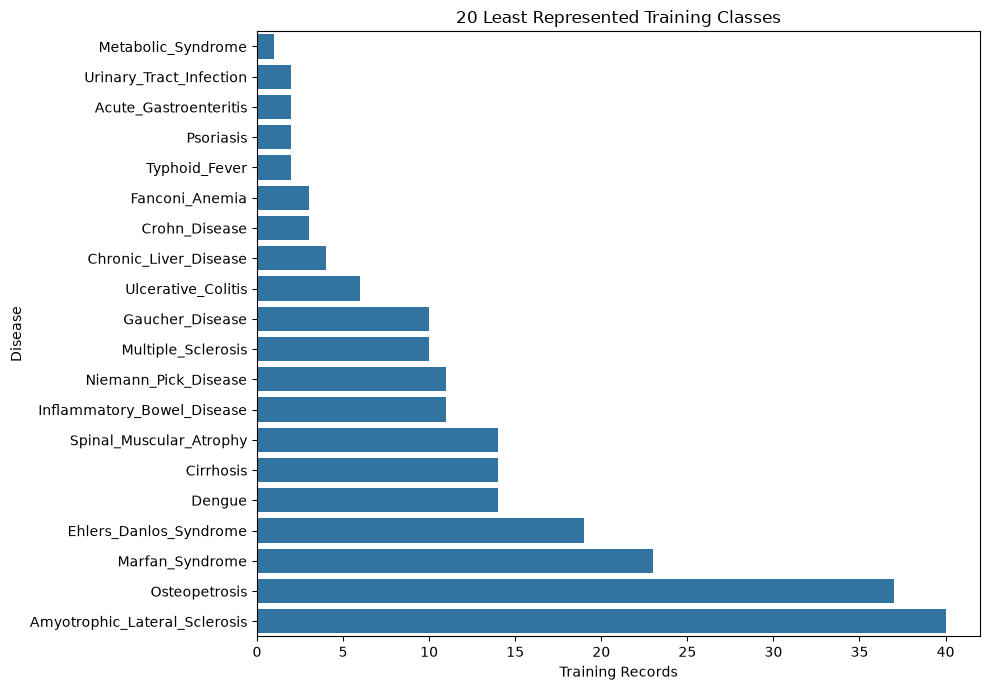

In [3]:
# Checking class imbalance in the training data
DATA_DIR = Path("../data/processed")
REPORT_DIR = Path("../reports")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["disease_encoded"]

label_encoder = __import__("joblib").load(
    DATA_DIR / "label_encoder.joblib"
)

class_counts = y_train.value_counts().sort_values()

class_distribution = pd.DataFrame({
    "class_id": class_counts.index,
    "records": class_counts.values
})

class_distribution["disease"] = label_encoder.inverse_transform(
    class_distribution["class_id"].to_numpy()
)

print("Number of training classes:", len(class_counts))
print("\n10 least represented classes:")
print(class_distribution.head(10).to_string(index=False))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=class_distribution.head(20),
    x="records",
    y="disease"
)
plt.title("20 Least Represented Training Classes")
plt.xlabel("Training Records")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()

In [4]:
# Training a class-weighted XGBoost model
import numpy as np
import time
import joblib

from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Load the existing test set
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["disease_encoded"]

# Calculate weights from training labels only
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

weighted_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=len(label_encoder.classes_),
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

weighted_xgb.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

training_time = time.time() - start_time

print(f"Training time: {training_time:.2f} seconds")

Training time: 92.06 seconds


In [5]:
# Evaluate the optimized model 
y_pred_weighted = weighted_xgb.predict(X_test)

weighted_metrics = {
    "Model": "XGBoost - Balanced Weights",
    "Accuracy": accuracy_score(y_test, y_pred_weighted),
    "Macro F1": f1_score(
        y_test,
        y_pred_weighted,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test,
        y_pred_weighted,
        average="weighted",
        zero_division=0
    ),
    "Training Time (seconds)": training_time
}

for metric, value in weighted_metrics.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

Model: XGBoost - Balanced Weights
Accuracy: 0.6612
Macro F1: 0.3526
Weighted F1: 0.6636
Training Time (seconds): 92.0605


In [6]:
# Saving the model and metrics
REPORT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    weighted_xgb,
    "../models/xgboost_weighted_model.joblib"
)

pd.DataFrame([weighted_metrics]).to_csv(
    REPORT_DIR / "xgboost_weighted_metrics.csv",
    index=False
)

print("Weighted XGBoost model and metrics saved.")

Weighted XGBoost model and metrics saved.


In [7]:
# Comparing against the original model
original = pd.read_csv(
    REPORT_DIR / "xgboost_metrics.csv"
).iloc[0]

optimized = pd.read_csv(
    REPORT_DIR / "xgboost_weighted_metrics.csv"
).iloc[0]

comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Accuracy": original["Accuracy"],
        "Macro F1": original["Macro F1"],
        "Weighted F1": original["Weighted F1"]
    },
    {
        "Model": "Class-Weighted XGBoost",
        "Accuracy": optimized["Accuracy"],
        "Macro F1": optimized["Macro F1"],
        "Weighted F1": optimized["Weighted F1"]
    }
])

display(comparison.round(4))

,Model,Accuracy,Macro F1,Weighted F1
0,Original XGBoost,0.6671,0.3446,0.6577
1,Class-Weighted XGBoost,0.6612,0.3526,0.6636
